# Arrival delay after departure: "the plane has left X minutes late, will it arrive 15+ minutes late?"

**Question:** given a flight that has just departed, how well can we predict whether it will **arrive** at least 15 minutes late?

**Prediction time = actual departure.** So the departure delay is a legitimate input here, together with:
schedule features, weather at the origin (observed 2+ hours before scheduled departure), trailing 30-day arrival-delay rates (previous days only), and **aircraft rotation features** from the tail number (how late was the plane's previous flight today, how many legs it has already flown, scheduled turnaround time).

**Files you need to upload when asked**
1. `flights_weather_2023.parquet` (output of the merge notebook)
2. The 12 monthly BTS files **with TAIL_NUM and ARR_DELAY**, all airports (`.zip`, `.csv` or `.xlsx`)

**Split (chronological):** train Jan-Sep, validation Oct, test Nov-Dec. The test set is used once, at the end.

In [ ]:
import json, time, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

# ------------------------------ settings ------------------------------
PARQUET_PATH   = "flights_weather_2023.parquet"
TAIL_DIR       = Path("tail_files")      # the 12 monthly files are stored here
RANDOM_STATE   = 42
WARMUP_DAYS    = 30
HIST_WINDOW    = 30
LR_C_GRID      = [0.01, 0.1, 1, 10]
RF_SEARCH_ITER = 6
RF_SEARCH_ROWS = 150_000
N_TREES_SEARCH = 100
N_TREES_FINAL  = 200
HGB_CONFIGS    = [dict(learning_rate=0.1,  max_leaf_nodes=31, min_samples_leaf=100),
                  dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=200),
                  dict(learning_rate=0.1,  max_leaf_nodes=15, min_samples_leaf=50)]
HGB_MAX_ITER   = 200
N_BOOT         = 200

## 1. Upload the parquet file

In [ ]:
if not Path(PARQUET_PATH).exists():
    found = sorted(Path(".").glob("*flights_weather*.parquet"))
    if found:
        PARQUET_PATH = str(found[0])
    else:
        try:
            from google.colab import files
            print("Upload flights_weather_2023.parquet ...")
            up = files.upload()
            PARQUET_PATH = list(up.keys())[0]
        except ImportError:
            raise FileNotFoundError("Put the parquet file next to this notebook or fix PARQUET_PATH")

pq = pd.read_parquet(PARQUET_PATH)
print(PARQUET_PATH, pq.shape)

Upload flights_weather_2023.parquet ...


Saving flights_weather_2023.parquet to flights_weather_2023.parquet
flights_weather_2023.parquet (474503, 40)


## 2. Upload the 12 monthly BTS files (tail number + arrival delay)

In the Colab upload dialog you can select all 12 files at once. They are saved to the `tail_files/` folder, so a re-run does not ask again.

In [ ]:
TAIL_DIR.mkdir(exist_ok=True)
ok_suffix = {".csv", ".zip", ".xlsx", ".xls"}
def list_tail_files():
    return sorted(p for p in TAIL_DIR.iterdir() if p.suffix.lower() in ok_suffix and not p.name.startswith("~$"))

paths = list_tail_files()
if len(paths) < 12:
    try:
        from google.colab import files
        print(f"{len(paths)} file(s) found. Upload the 12 monthly BTS files (select all of them) ...")
        up = files.upload()
        for name, data in up.items():
            (TAIL_DIR / name).write_bytes(data)
        paths = list_tail_files()
    except ImportError:
        print(f"Only {len(paths)} file(s) in {TAIL_DIR}/ - copy the monthly files there.")
print(len(paths), "monthly file(s):", [p.name for p in paths])
if len(paths) != 12:
    print("WARNING: expected 12 files. The notebook will continue with what it has.")

0 file(s) found. Upload the 12 monthly BTS files (select all of them) ...


Saving T_ONTIME_REPORTING_20261025_134932.zip to T_ONTIME_REPORTING_20261025_134932.zip
Saving T_ONTIME_REPORTING_20261025_134707.zip to T_ONTIME_REPORTING_20261025_134707.zip
Saving T_ONTIME_REPORTING_20261025_134429.zip to T_ONTIME_REPORTING_20261025_134429.zip
Saving T_ONTIME_REPORTING_20261025_134202.zip to T_ONTIME_REPORTING_20261025_134202.zip
Saving T_ONTIME_REPORTING_20261025_133905.zip to T_ONTIME_REPORTING_20261025_133905.zip
Saving T_ONTIME_REPORTING_20261025_133632.zip to T_ONTIME_REPORTING_20261025_133632.zip
Saving T_ONTIME_REPORTING_20261025_133531.zip to T_ONTIME_REPORTING_20261025_133531.zip
Saving T_ONTIME_REPORTING_20261025_133256.zip to T_ONTIME_REPORTING_20261025_133256.zip
Saving T_ONTIME_REPORTING_20261025_132957.zip to T_ONTIME_REPORTING_20261025_132957.zip
Saving T_ONTIME_REPORTING_20261025_132645.zip to T_ONTIME_REPORTING_20261025_132645.zip
Saving T_ONTIME_REPORTING_20261025_132425.zip to T_ONTIME_REPORTING_20261025_132425.zip
Saving T_ONTIME_REPORTING_202610

In [ ]:
NEEDED = {"FL_DATE", "YEAR", "MONTH", "DAY_OF_MONTH", "OP_UNIQUE_CARRIER", "TAIL_NUM", "OP_CARRIER_FL_NUM",
          "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME", "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED"}
use = lambda col: str(col).strip().upper() in NEEDED

def read_one(path):
    s = path.suffix.lower()
    if s == ".csv":
        return [pd.read_csv(path, usecols=use, low_memory=False)]
    if s in (".xlsx", ".xls"):
        return list(pd.read_excel(path, sheet_name=None, usecols=use).values())
    out = []
    with zipfile.ZipFile(path) as zf:
        for name in zf.namelist():
            if name.lower().endswith(".csv"):
                with zf.open(name) as fh:
                    out.append(pd.read_csv(fh, usecols=use, low_memory=False))
    return out

parts, per_file = [], []
for p in paths:
    for d in read_one(p):
        d.columns = d.columns.str.strip().str.upper()
        per_file.append({"file": p.name, "rows": len(d), "columns": ", ".join(d.columns)})
        parts.append(d)
tail = pd.concat(parts, ignore_index=True)
del parts
print(pd.DataFrame(per_file)[["file", "rows"]].to_string(index=False))
print("\ncolumns found:", sorted(tail.columns))

REQUIRED = ["TAIL_NUM", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME", "ARR_DELAY"]
missing_req = [c for c in REQUIRED if c not in tail.columns]
if "FL_DATE" not in tail.columns and not {"YEAR", "MONTH", "DAY_OF_MONTH"} <= set(tail.columns):
    missing_req.append("FL_DATE")
if missing_req:
    raise ValueError(
        f"The monthly files are missing these columns: {missing_req}.\n"
        "Re-download the 12 months from BTS TranStats with these fields ticked: FL_DATE, TAIL_NUM, "
        "OP_CARRIER_FL_NUM, ORIGIN, DEST, CRS_DEP_TIME, ARR_DELAY (recommended: DEP_DELAY, CRS_ARR_TIME, CANCELLED, DIVERTED; "
        "the airline code is optional).")
HAS_CARRIER = "OP_UNIQUE_CARRIER" in tail.columns
if not HAS_CARRIER:
    print("note: no airline column in the files -> flights are matched on date + flight number + origin + destination + scheduled time (checked: this is unique)")
for c in ["DEP_DELAY", "CRS_ARR_TIME", "CANCELLED", "DIVERTED"]:
    if c not in tail.columns:
        print(f"note: optional column {c} not in the files -> features that need it are skipped")
        tail[c] = np.nan

                                  file   rows
T_ONTIME_REPORTING_20261025_132210.zip 538837
T_ONTIME_REPORTING_20261025_132425.zip 502749
T_ONTIME_REPORTING_20261025_132645.zip 580322
T_ONTIME_REPORTING_20261025_132957.zip 561441
T_ONTIME_REPORTING_20261025_133256.zip 579958
T_ONTIME_REPORTING_20261025_133531.zip 577262
T_ONTIME_REPORTING_20261025_133632.zip 601866
T_ONTIME_REPORTING_20261025_133905.zip 602987
T_ONTIME_REPORTING_20261025_134202.zip 569338
T_ONTIME_REPORTING_20261025_134429.zip 598968
T_ONTIME_REPORTING_20261025_134707.zip 563777
T_ONTIME_REPORTING_20261025_134932.zip 570394

columns found: ['ARR_DELAY', 'CANCELLED', 'CRS_ARR_TIME', 'CRS_DEP_TIME', 'DEP_DELAY', 'DEST', 'FL_DATE', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'TAIL_NUM']
note: no airline column in the files -> flights are matched on date + flight number + origin + destination + scheduled time (checked: this is unique)
note: optional column DIVERTED not in the files -> features that need it are skipped


## 3. Clean the BTS files and build the aircraft-rotation features

For every flight we look up the **previous flight of the same aircraft on the same day** (it must have landed at this flight's origin airport). Those facts are known by the time our flight departs, because the plane has to arrive before it can leave again.

In [ ]:
def parse_fl_date(s):
    if "FL_DATE" in s.columns:
        out = pd.to_datetime(s["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
        if out.isna().mean() > 0.01:
            out = pd.to_datetime(s["FL_DATE"], errors="coerce")
    else:
        out = pd.to_datetime(dict(year=s["YEAR"], month=s["MONTH"], day=s["DAY_OF_MONTH"]), errors="coerce")
    return out.dt.normalize().astype("datetime64[ns]")

tail["FL_DATE"] = parse_fl_date(tail)
for c in ["OP_CARRIER_FL_NUM", "CRS_DEP_TIME", "CRS_ARR_TIME", "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED"]:
    tail[c] = pd.to_numeric(tail[c], errors="coerce")
for c in ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "TAIL_NUM"]:
    if c in tail.columns:
        tail[c] = tail[c].astype("string").str.strip().str.upper()

n0 = len(tail)
tail = tail.dropna(subset=["FL_DATE", "OP_CARRIER_FL_NUM", "CRS_DEP_TIME"])
tail = tail[~((tail["CANCELLED"] == 1) | (tail["DIVERTED"] == 1))]
tail = tail.drop_duplicates()
tail["OP_CARRIER_FL_NUM"] = tail["OP_CARRIER_FL_NUM"].astype("int64")
tail["CRS_DEP_TIME"] = tail["CRS_DEP_TIME"].astype("int64")
print(f"BTS rows: {n0:,} -> {len(tail):,} after removing cancelled / diverted / duplicate rows")
print(f"rows with a tail number: {tail['TAIL_NUM'].notna().mean():.1%}, with ARR_DELAY: {tail['ARR_DELAY'].notna().mean():.1%}")

# integer airport codes make the 'previous flight landed here' check fast
airports = pd.Index(sorted(set(tail["ORIGIN"].dropna()) | set(tail["DEST"].dropna())))
tail["_o"] = airports.get_indexer(tail["ORIGIN"]).astype("int16")
tail["_d"] = airports.get_indexer(tail["DEST"]).astype("int16")
tail["_dep_min"] = (tail["CRS_DEP_TIME"] // 100) * 60 + tail["CRS_DEP_TIME"] % 100
tail["_arr_min"] = (tail["CRS_ARR_TIME"] // 100) * 60 + tail["CRS_ARR_TIME"] % 100
tail["TAIL_NUM"] = tail["TAIL_NUM"].astype("category")

BTS rows: 6,847,899 -> 6,759,956 after removing cancelled / diverted / duplicate rows
rows with a tail number: 100.0%, with ARR_DELAY: 99.8%


In [ ]:
t = tail[tail["TAIL_NUM"].notna()].sort_values(["TAIL_NUM", "FL_DATE", "_dep_min", "OP_CARRIER_FL_NUM"], kind="mergesort")
g = t.groupby(["TAIL_NUM", "FL_DATE"], sort=False, observed=True)

t["tail_leg_of_day"] = g.cumcount() + 1
prev = g[["_d", "ARR_DELAY", "DEP_DELAY", "_arr_min"]].shift(1)
chain_ok = prev["_d"].eq(t["_o"])                    # previous leg landed at THIS flight's origin
t["prev_arr_delay"] = prev["ARR_DELAY"].where(chain_ok)
t["prev_dep_delay"] = prev["DEP_DELAY"].where(chain_ok)
turn = (t["_dep_min"] - prev["_arr_min"]).where(chain_ok)
t["sched_turn_min"] = turn.where(turn >= 0)           # scheduled minutes on the ground

# average arrival delay of all EARLIER legs of the same aircraft the same day
arr0 = t["ARR_DELAY"].fillna(0); valid = t["ARR_DELAY"].notna().astype(float)
t["_arr0"], t["_valid"] = arr0, valid
cum_sum = g["_arr0"].cumsum() - arr0
cum_n = g["_valid"].cumsum() - valid
t["prev_legs_mean_arr_delay"] = (cum_sum / cum_n.where(cum_n > 0))

TAIL_FEATS = ["tail_leg_of_day", "prev_arr_delay", "prev_dep_delay", "sched_turn_min", "prev_legs_mean_arr_delay"]
KEYS_TAIL = ["FL_DATE"] + (["OP_UNIQUE_CARRIER"] if HAS_CARRIER else []) + ["OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
slim = tail[KEYS_TAIL + ["ARR_DELAY"]].join(t[TAIL_FEATS])
dups = slim.duplicated(KEYS_TAIL).sum()
slim = slim.drop_duplicates(KEYS_TAIL, keep="first")
slim["ORIGIN"] = slim["ORIGIN"].astype(str); slim["DEST"] = slim["DEST"].astype(str)
if HAS_CARRIER:
    slim["OP_UNIQUE_CARRIER"] = slim["OP_UNIQUE_CARRIER"].astype(str)
print(f"rows with a valid previous leg: {slim['prev_arr_delay'].notna().mean():.1%}   duplicate flight keys removed: {dups:,}")
print(slim[TAIL_FEATS].describe().round(1).T)
del t, g, prev, tail

rows with a valid previous leg: 74.6%   duplicate flight keys removed: 14
                              count  mean   std   min   25%   50%   75%     max
tail_leg_of_day           6759942.0   2.9   1.7   1.0   2.0   3.0   4.0    13.0
prev_arr_delay            5042835.0   2.5  39.3 -98.0 -15.0  -6.0   7.0  4405.0
prev_dep_delay            5051233.0   8.0  36.5 -99.0  -6.0  -2.0   6.0  4413.0
sched_turn_min            4998232.0  75.6  83.2   0.0  45.0  56.0  71.0  1437.0
prev_legs_mean_arr_delay  5096718.0   0.2  34.6 -97.0 -14.0  -7.0   3.0  4405.0


## 4. Merge with the parquet and build the target

Each flight in the parquet is matched on **date + airline + flight number + origin + destination + scheduled departure time**.
The label is `arr_del15 = ARR_DELAY >= 15`.

In [ ]:
df = pq.copy()
df["flight_date"] = df["flight_date"].astype("datetime64[ns]")
for c in ["airline", "origin", "dest"]:
    df[c] = df[c].astype(str)
df["flight_number"] = df["flight_number"].astype("int64"); df["crs_dep_time"] = df["crs_dep_time"].astype("int64")

n = len(df)
left_keys = ["flight_date"] + (["airline"] if HAS_CARRIER else []) + ["flight_number", "origin", "dest", "crs_dep_time"]
df = df.merge(slim, left_on=left_keys, right_on=KEYS_TAIL, how="left", validate="many_to_one")
assert len(df) == n, "merge changed the number of flights"
df = df.drop(columns=KEYS_TAIL)

matched = df["ARR_DELAY"].notna()
by_month = pd.DataFrame({"flights": df.groupby("month").size(), "with ARR_DELAY": df.groupby("month")["ARR_DELAY"].count()})
by_month["share"] = (by_month["with ARR_DELAY"] / by_month["flights"]).round(3)
print(by_month.T.to_string())
print(f"\nflights with an arrival delay: {matched.mean():.1%} (the rest are diverted flights or flights missing from the monthly files)")
if matched.mean() < 0.95:
    print("WARNING: less than 95% matched. Check that all 12 months were uploaded and were downloaded for ALL airports.")

df = df[matched].copy()
df = df.rename(columns={"ARR_DELAY": "arr_delay_min"})
df["arr_del15"] = (df["arr_delay_min"] >= 15).astype("int8")
print("\nsanity check - arrival-late rate by departure status:")
print(df.groupby("dep_del15")["arr_del15"].agg(["size", "mean"]).round(3).rename(index={0: "left <15 min late", 1: "left 15+ min late"}))
print("corr(departure delay, arrival delay) = %.3f" % df[["dep_delay_min", "arr_delay_min"]].corr().iloc[0, 1])

month                  1          2          3          4          5          6          7          8          9          10         11         12
flights         37145.000  34275.000  39327.000  38589.000  40657.000  39661.000  40994.000  41772.000  40241.000  42472.000  39708.000  39662.000
with ARR_DELAY  37097.000  34203.000  39248.000  38496.000  40555.000  39531.000  40818.000  41615.000  40167.000  42434.000  39683.000  39629.000
share               0.999      0.998      0.998      0.998      0.997      0.997      0.996      0.996      0.998      0.999      0.999      0.999

flights with an arrival delay: 99.8% (the rest are diverted flights or flights missing from the monthly files)

sanity check - arrival-late rate by departure status:
                     size   mean
dep_del15                       
left <15 min late  361860  0.065
left 15+ min late  111616  0.791
corr(departure delay, arrival delay) = 0.971


## 5. Features

Known at the moment of departure: schedule, weather (2h before scheduled departure), **the actual departure delay**, aircraft-rotation features, and trailing 30-day **arrival**-delay rates from earlier days only.

In [ ]:
# two known-bad wind readings in the source weather -> empty
bad_wind = ((df["wx_gust_kt"] < df["wx_wind_kt"]) & (df["wx_has_gust"] == 1)) | \
           ((df["wx_wind_kt"] >= 35) & (df["wx_has_gust"] == 0))
df.loc[bad_wind, "wx_wind_kt"] = np.nan

cal = USFederalHolidayCalendar()
holidays = cal.holidays(start="2022-12-01", end="2024-01-31")
days = pd.date_range(df["flight_date"].min() - pd.Timedelta(days=10), df["flight_date"].max() + pd.Timedelta(days=10))
near = pd.Series(0, index=days)
for h in holidays:
    near.loc[h - pd.Timedelta(days=3): h + pd.Timedelta(days=3)] = 1
df["is_holiday_window"] = df["flight_date"].map(near).fillna(0).astype(int)

def add_trailing_rate(data, keys, name, target, window_days=HIST_WINDOW, min_n=20):
    daily = (data.groupby(keys + ["flight_date"])[target].agg(n="size", k="sum")
                 .reset_index().sort_values("flight_date").set_index("flight_date"))
    roll = daily.groupby(keys)[["n", "k"]].rolling(f"{window_days}D", closed="left").sum().reset_index()
    roll[name] = np.where(roll["n"] >= min_n, roll["k"] / roll["n"], np.nan)    # previous days only
    return data.merge(roll[keys + ["flight_date", name]], on=keys + ["flight_date"], how="left")

n = len(df)
df = add_trailing_rate(df, ["route"], "hist_route_arr_rate", "arr_del15", min_n=20)
df = add_trailing_rate(df, ["airline"], "hist_airline_arr_rate", "arr_del15", min_n=50)
df = add_trailing_rate(df, ["origin"], "hist_origin_arr_rate", "arr_del15", min_n=50)
assert len(df) == n

# departure delay: clipped value + simple step features (helps the linear model)
df["dep_delay_clip"] = df["dep_delay_min"].clip(-30, 300)
df["dep_late_15"] = (df["dep_delay_min"] >= 15).astype(int)
df["dep_late_30"] = (df["dep_delay_min"] >= 30).astype(int)
df["dep_late_60"] = (df["dep_delay_min"] >= 60).astype(int)

for c in ["sched_dep_hour", "day_of_week"]:
    df[c] = df[c].astype(str)
df["wx_sky_cover"] = df["wx_sky_cover"].fillna("UNK").astype(str)

CAT = ["airline", "origin", "dest", "sched_dep_hour", "day_of_week", "wx_sky_cover"]
WX_FLAGS = ["wx_has_gust", "wx_rain", "wx_snow", "wx_thunder", "wx_fog", "wx_mist", "wx_drizzle",
            "wx_haze", "wx_freezing", "wx_ice_hail", "wx_heavy"]
NUM = (["distance_mi", "crs_elapsed_min", "is_holiday_window", "wx_temp_f", "wx_wind_kt", "wx_gust_kt", "wx_vis_mi",
        "wx_precip_1h_in", "wx_ceiling_ft"] + WX_FLAGS +
       ["hist_route_arr_rate", "hist_airline_arr_rate", "hist_origin_arr_rate"] +
       ["dep_delay_clip", "dep_late_15", "dep_late_30", "dep_late_60"] +
       [c for c in TAIL_FEATS if df[c].notna().any()])
FEATURES = CAT + NUM

# leakage guard: the arrival outcome itself must never be an input
FORBIDDEN = {"arr_delay_min", "arr_del15", "split", "wx_obs_utc", "wx_cutoff_utc", "wx_age_min",
             "sched_dep_utc", "sched_dep_local", "flight_date", "month", "dep_delay_min", "dep_del15"}
assert not (set(FEATURES) & FORBIDDEN), "a forbidden column is in the feature list"
print(len(FEATURES), "features")
print("aircraft-rotation features used:", [c for c in TAIL_FEATS if c in NUM])

38 features
aircraft-rotation features used: ['tail_leg_of_day', 'prev_arr_delay', 'prev_dep_delay', 'sched_turn_min', 'prev_legs_mean_arr_delay']


## 6. Chronological split

In [ ]:
first_day = df["flight_date"].min() + pd.Timedelta(days=WARMUP_DAYS)
model_df = df[df["flight_date"] >= first_day]
print(f"dropped {len(df) - len(model_df):,} warm-up flights (before {first_day.date()})")

train = model_df[model_df["split"] == "train"].reset_index(drop=True)
val   = model_df[model_df["split"] == "validation"].reset_index(drop=True)
test  = model_df[model_df["split"] == "test"].reset_index(drop=True)
for name, d in [("train", train), ("validation", val), ("test", test)]:
    if len(d) == 0:
        raise ValueError(f"{name} set is empty - check that all 12 months matched")

X_train, y_train = train[FEATURES], train["arr_del15"].values
X_val,   y_val   = val[FEATURES],   val["arr_del15"].values
X_test,  y_test  = test[FEATURES],  test["arr_del15"].values
print(pd.DataFrame({"flights": [len(train), len(val), len(test)],
                    "arrival_late_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
                    "from": [d.flight_date.min().date() for d in (train, val, test)],
                    "to":   [d.flight_date.max().date() for d in (train, val, test)]},
                   index=["train", "validation", "test"]).round(3))
print("\nMissing values in training features (filled with the training median):")
print(X_train.isna().mean()[lambda s: s > 0].round(3).to_string())

dropped 36,078 warm-up flights (before 2023-01-31)
            flights  arrival_late_rate        from          to
train        315652              0.264  2023-01-31  2023-09-30
validation    42434              0.179  2023-10-01  2023-10-31
test          79312              0.153  2023-11-01  2023-12-31

Missing values in training features (filled with the training median):
wx_temp_f                   0.000
wx_wind_kt                  0.000
wx_gust_kt                  0.000
wx_vis_mi                   0.000
wx_precip_1h_in             0.000
wx_ceiling_ft               0.000
wx_has_gust                 0.000
wx_rain                     0.000
wx_snow                     0.000
wx_thunder                  0.000
wx_fog                      0.000
wx_mist                     0.000
wx_drizzle                  0.000
wx_haze                     0.000
wx_freezing                 0.000
wx_ice_hail                 0.000
wx_heavy                    0.000
hist_airline_arr_rate       0.001
prev_arr_dela

## 7. Helper functions

In [ ]:
def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.argmax(f1[:-1])])

def metrics_at(y, s, thr):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": round(float(thr), 4),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def make_preprocessor(for_linear):
    num = [("imp", SimpleImputer(strategy="median"))]
    if for_linear:
        num.append(("scale", StandardScaler()))
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=for_linear, dtype=np.float32)
    return ColumnTransformer([("num", Pipeline(num), NUM), ("cat", ohe, CAT)],
                             sparse_threshold=0.3 if for_linear else 0.0)

scores_val, scores_test = {}, {}

## 8. Baselines

1. **Majority class:** always predicts "arrives on time".
2. **Departure-delay rule:** the obvious simple rule, "if the plane left X minutes late it will arrive late". The score is the departure delay itself and X is chosen on validation. **This is the baseline the models have to beat.**

In [ ]:
scores_val["Departure-delay rule"]  = val["dep_delay_min"].clip(-60, 600).values.astype(float)
scores_test["Departure-delay rule"] = test["dep_delay_min"].clip(-60, 600).values.astype(float)
scores_val["Majority-class baseline"]  = np.zeros(len(val))
scores_test["Majority-class baseline"] = np.zeros(len(test))
print("baselines ready")

baselines ready


## 9. Logistic regression (tuned on validation PR-AUC)

In [ ]:
t0 = time.time()
prep_lr = make_preprocessor(True).fit(X_train)
Xtr, Xva = prep_lr.transform(X_train), prep_lr.transform(X_val)
rows, best = [], None
for C in LR_C_GRID:
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=1000).fit(Xtr, y_train)
    ap = average_precision_score(y_val, clf.predict_proba(Xva)[:, 1])
    rows.append({"C": C, "validation PR-AUC": round(ap, 4)})
    if best is None or ap > best[0]:
        best = (ap, C, clf)
print(pd.DataFrame(rows).to_string(index=False)); print(f"best C = {best[1]} ({time.time()-t0:.0f}s)")
lr_pipe = Pipeline([("prep", prep_lr), ("clf", best[2])])
scores_val["Logistic regression"]  = lr_pipe.predict_proba(X_val)[:, 1]
scores_test["Logistic regression"] = lr_pipe.predict_proba(X_test)[:, 1]

    C  validation PR-AUC
 0.01             0.8466
 0.10             0.8474
 1.00             0.8476
10.00             0.8476
best C = 1 (33s)


## 10. Random forest (random search on validation PR-AUC)

In [ ]:
t0 = time.time()
prep_rf = make_preprocessor(False).fit(X_train)
Xtr_rf, Xva_rf = prep_rf.transform(X_train), prep_rf.transform(X_val)
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(Xtr_rf), size=min(RF_SEARCH_ROWS, len(Xtr_rf)), replace=False)
grid = {"max_depth": [8, 12, 16, 24], "min_samples_leaf": [20, 50, 100, 200], "max_features": ["sqrt", 0.3, 0.5]}
best_rf = None
for params in ParameterSampler(grid, n_iter=RF_SEARCH_ITER, random_state=RANDOM_STATE):
    rf = RandomForestClassifier(n_estimators=N_TREES_SEARCH, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=RANDOM_STATE, **params).fit(Xtr_rf[idx], y_train[idx])
    ap = average_precision_score(y_val, rf.predict_proba(Xva_rf)[:, 1])
    print(f"  {params} -> {ap:.4f} ({time.time()-t0:.0f}s)")
    if best_rf is None or ap > best_rf[0]:
        best_rf = (ap, params)
rf_final = RandomForestClassifier(n_estimators=N_TREES_FINAL, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=RANDOM_STATE, **best_rf[1]).fit(Xtr_rf, y_train)
rf_pipe = Pipeline([("prep", prep_rf), ("clf", rf_final)])
scores_val["Random forest"]  = rf_pipe.predict_proba(X_val)[:, 1]
scores_test["Random forest"] = rf_pipe.predict_proba(X_test)[:, 1]
print("best:", best_rf[1], f"({time.time()-t0:.0f}s)")

  {'min_samples_leaf': 200, 'max_features': 'sqrt', 'max_depth': 16} -> 0.8407 (49s)
  {'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 24} -> 0.8460 (139s)
  {'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 16} -> 0.8426 (170s)
  {'min_samples_leaf': 200, 'max_features': 0.3, 'max_depth': 24} -> 0.8438 (237s)
  {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16} -> 0.8447 (269s)
  {'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 24} -> 0.8440 (302s)
best: {'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 24} (750s)


## 11. Gradient boosting (a few settings, chosen on validation PR-AUC)

In [ ]:
t0 = time.time()
best_hgb = None
for cfg in HGB_CONFIGS:
    h = HistGradientBoostingClassifier(max_iter=HGB_MAX_ITER, class_weight="balanced", random_state=RANDOM_STATE, **cfg)
    h.fit(Xtr_rf, y_train)
    ap = average_precision_score(y_val, h.predict_proba(Xva_rf)[:, 1])
    print(f"  {cfg} -> {ap:.4f} ({time.time()-t0:.0f}s)")
    if best_hgb is None or ap > best_hgb[0]:
        best_hgb = (ap, cfg, h)
hgb_pipe = Pipeline([("prep", prep_rf), ("clf", best_hgb[2])])
scores_val["Gradient boosting"]  = hgb_pipe.predict_proba(X_val)[:, 1]
scores_test["Gradient boosting"] = hgb_pipe.predict_proba(X_test)[:, 1]

  {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} -> 0.8508 (52s)
  {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 200} -> 0.8514 (129s)
  {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 50} -> 0.8505 (171s)


## 12. Final scores

Thresholds are chosen on validation (best F1), then applied unchanged to the test set.

In [ ]:
MODELS = ["Majority-class baseline", "Departure-delay rule", "Logistic regression", "Random forest", "Gradient boosting"]
FITTED = MODELS[2:]
thresholds = {"Majority-class baseline": 1.0}      # scores are all 0, so it never predicts "late"
for m in MODELS[1:]:
    thresholds[m] = best_f1_threshold(y_val, scores_val[m])

val_table  = pd.DataFrame({m: metrics_at(y_val,  scores_val[m],  thresholds[m]) for m in MODELS}).T
test_table = pd.DataFrame({m: metrics_at(y_test, scores_test[m], thresholds[m]) for m in MODELS}).T
show = ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
print("VALIDATION (October)"); print(val_table[show].astype(float).round(3).to_string())
print("\nTEST (November-December), same thresholds"); print(test_table[show].astype(float).round(3).to_string())
print("\nTEST confusion counts"); print(test_table[["tn", "fp", "fn", "tp"]].astype(int).to_string())
print(f"\nShare of flights arriving 15+ min late in the test set: {y_test.mean():.3f}")

VALIDATION (October)
                         threshold  accuracy  precision  recall     f1  roc_auc  pr_auc
Majority-class baseline      1.000     0.821      0.000   0.000  0.000    0.500   0.179
Departure-delay rule        20.000     0.924      0.841   0.706  0.767    0.910   0.834
Logistic regression          0.647     0.925      0.832   0.723  0.774    0.920   0.848
Random forest                0.577     0.925      0.837   0.721  0.774    0.917   0.846
Gradient boosting            0.672     0.928      0.864   0.706  0.777    0.923   0.851

TEST (November-December), same thresholds
                         threshold  accuracy  precision  recall     f1  roc_auc  pr_auc
Majority-class baseline      1.000     0.847      0.000   0.000  0.000    0.500   0.153
Departure-delay rule        20.000     0.928      0.808   0.694  0.746    0.905   0.810
Logistic regression          0.647     0.929      0.807   0.705  0.753    0.915   0.825
Random forest                0.577     0.928      0.801 

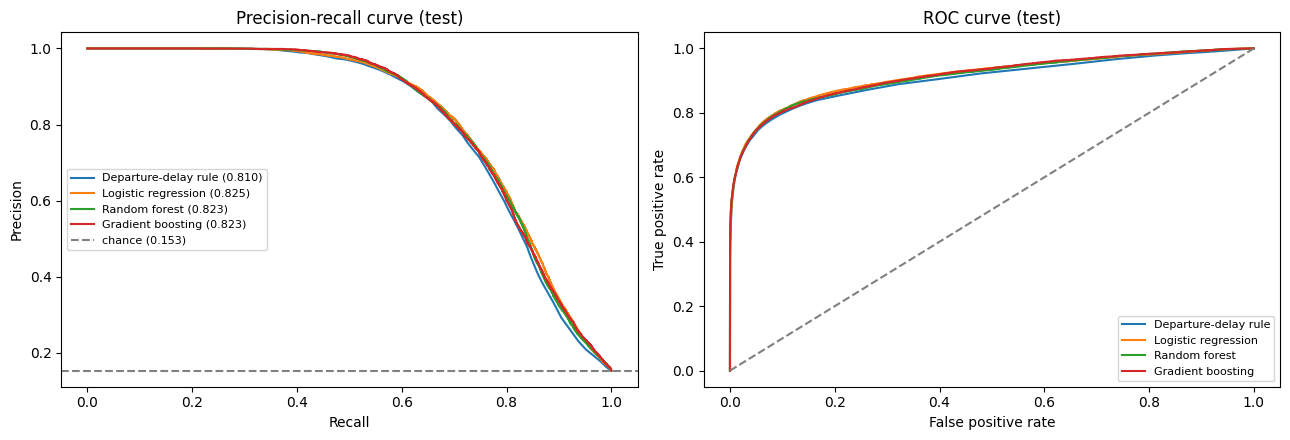

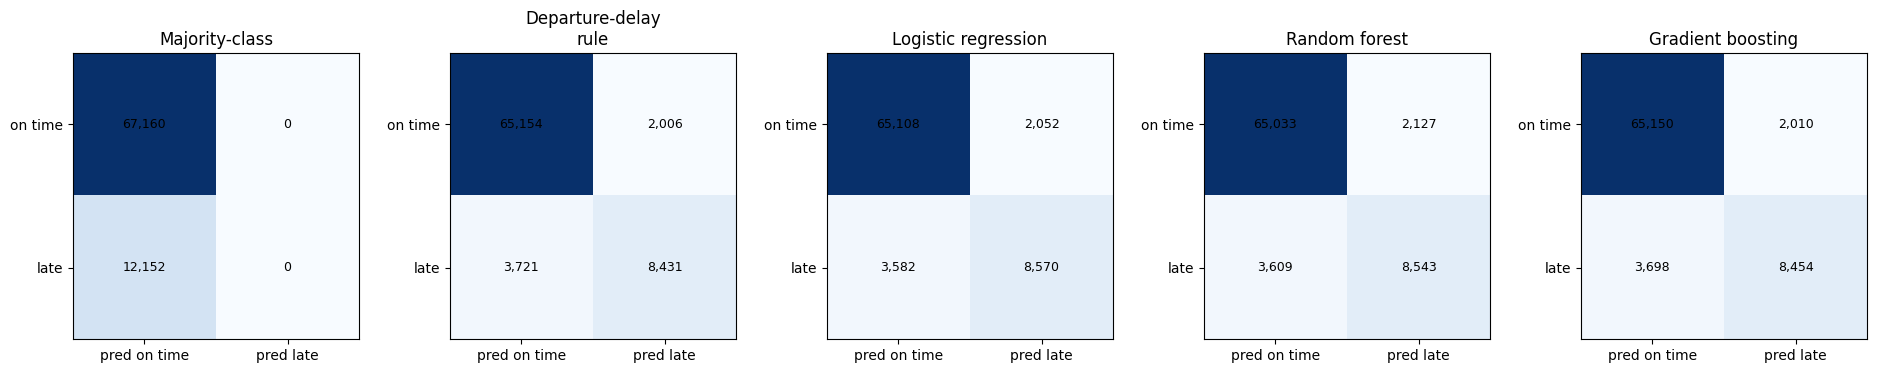

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m in MODELS[1:]:
    p, r, _ = precision_recall_curve(y_test, scores_test[m])
    ax[0].plot(r, p, label=f"{m} ({average_precision_score(y_test, scores_test[m]):.3f})")
    fpr, tpr, _ = roc_curve(y_test, scores_test[m]); ax[1].plot(fpr, tpr, label=m)
ax[0].axhline(y_test.mean(), color="gray", ls="--", label=f"chance ({y_test.mean():.3f})")
ax[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
for a, m in zip(axes, MODELS):
    r = test_table.loc[m]; cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=float)
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{int(cm[i, j]):,}", ha="center", va="center", fontsize=9)
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred on time", "pred late"], yticklabels=["on time", "late"],
          title=m.replace(" baseline", "").replace(" rule", "\nrule"))
plt.tight_layout(); plt.show()

### Do the models really beat the departure-delay rule? (bootstrap on the test set)

In [ ]:
rng = np.random.RandomState(RANDOM_STATE); nt = len(y_test)
boot = {m: [] for m in MODELS[1:]}
for _ in range(N_BOOT):
    i = rng.randint(0, nt, nt)
    for m in MODELS[1:]:
        boot[m].append(average_precision_score(y_test[i], scores_test[m][i]))
boot = {m: np.array(v) for m, v in boot.items()}
rows = []
for m in FITTED:
    gain = boot[m] - boot["Departure-delay rule"]
    lo, hi = np.percentile(gain, [2.5, 97.5])
    rows.append({"model": m, "PR-AUC gain vs departure-delay rule": round(gain.mean(), 4),
                 "95% interval": f"[{lo:.4f}, {hi:.4f}]", "gain larger than noise?": "yes" if lo > 0 else "no"})
boot_table = pd.DataFrame(rows); print(boot_table.to_string(index=False))

              model  PR-AUC gain vs departure-delay rule     95% interval gain larger than noise?
Logistic regression                               0.0151 [0.0137, 0.0166]                     yes
      Random forest                               0.0128 [0.0115, 0.0142]                     yes
  Gradient boosting                               0.0129 [0.0112, 0.0146]                     yes


### Scores by period and by how the flight departed (test set)

In [ ]:
def group_scores(mask, label):
    out = []
    for m in MODELS[1:]:
        s, y = scores_test[m][mask], y_test[mask]
        if y.sum() == 0 or y.sum() == len(y):
            continue
        r = metrics_at(y, s, thresholds[m])
        out.append({"group": label, "model": m, "flights": int(mask.sum()), "arrival_late_rate": round(y.mean(), 3),
                    "precision": round(r["precision"], 3), "recall": round(r["recall"], 3),
                    "f1": round(r["f1"], 3), "pr_auc": round(r["pr_auc"], 3)})
    return out
rows = []
for mth, name in [(11, "November"), (12, "December")]:
    rows += group_scores((test["month"] == mth).values, name)
rows += group_scores((test["dep_del15"] == 0).values, "left on time (<15 min late)")
rows += group_scores((test["dep_del15"] == 1).values, "left 15+ min late")
print(pd.DataFrame(rows).to_string(index=False))

                      group                model  flights  arrival_late_rate  precision  recall    f1  pr_auc
                   November Departure-delay rule    39683              0.146      0.815   0.681 0.742   0.804
                   November  Logistic regression    39683              0.146      0.813   0.696 0.750   0.823
                   November        Random forest    39683              0.146      0.810   0.694 0.747   0.821
                   November    Gradient boosting    39683              0.146      0.820   0.686 0.747   0.821
                   December Departure-delay rule    39629              0.160      0.801   0.706 0.751   0.816
                   December  Logistic regression    39629              0.160      0.802   0.714 0.755   0.827
                   December        Random forest    39629              0.160      0.792   0.712 0.750   0.824
                   December    Gradient boosting    39629              0.160      0.798   0.704 0.748   0.824
left on ti

### What the models use

best model on validation PR-AUC: Gradient boosting


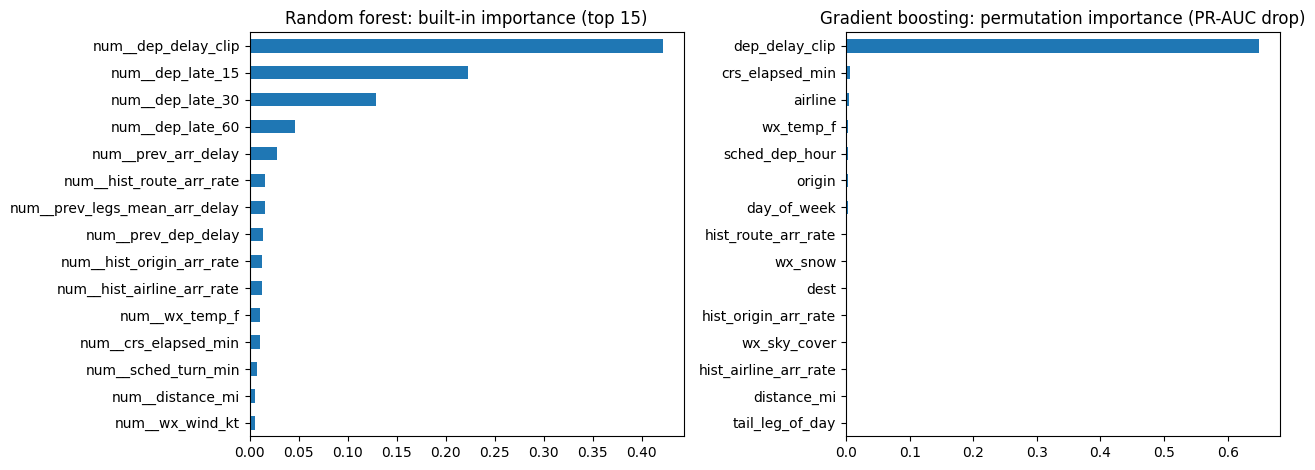

In [ ]:
names = prep_rf.get_feature_names_out()
imp = pd.Series(rf_final.feature_importances_, index=names).sort_values(ascending=False).head(15)
best_name = max(FITTED, key=lambda m: average_precision_score(y_val, scores_val[m]))
best_pipe = {"Logistic regression": lr_pipe, "Random forest": rf_pipe, "Gradient boosting": hgb_pipe}[best_name]
print("best model on validation PR-AUC:", best_name)
smp = val.sample(min(10000, len(val)), random_state=RANDOM_STATE)
pi = permutation_importance(best_pipe, smp[FEATURES], smp["arr_del15"], scoring="average_precision",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
imp[::-1].plot.barh(ax=ax[0]); ax[0].set_title("Random forest: built-in importance (top 15)")
perm[::-1].plot.barh(ax=ax[1]); ax[1].set_title(f"{best_name}: permutation importance (PR-AUC drop)")
plt.tight_layout(); plt.show()

## 13. Final scorecard and files

In [ ]:
final = test_table[show + ["tn", "fp", "fn", "tp"]].copy()
final[show] = final[show].astype(float).round(3)
final[["tn", "fp", "fn", "tp"]] = final[["tn", "fp", "fn", "tp"]].astype(int)
print("=" * 86)
print("FINAL SCORECARD - ARRIVAL DELAY AFTER DEPARTURE - TEST SET (Nov-Dec 2023)")
print("=" * 86)
print(final.to_string())
print()
best_test = test_table.loc[FITTED, "pr_auc"].astype(float).idxmax()
print(f"Best model by test PR-AUC: {best_test}")
print(f"Flights arriving 15+ min late in the test set: {int(y_test.sum()):,} of {len(y_test):,} ({y_test.mean():.1%})")
print(boot_table.to_string(index=False))

final.to_csv("arrival_model_scores_test.csv")
val_table[show + ["tn", "fp", "fn", "tp"]].to_csv("arrival_model_scores_validation.csv")

grid_t = np.round(np.arange(0, 1.0001, 0.01), 2)
web = {"task": "arrival delay (15+ min) after departure", "test_period": "2023-11 to 2023-12",
       "n_test": int(len(y_test)), "late_rate_test": float(y_test.mean()), "models": {}}
for m in FITTED:
    s = scores_test[m]; rows = []
    for th in grid_t:
        pred = s >= th
        tp = int((pred & (y_test == 1)).sum()); fp = int((pred & (y_test == 0)).sum())
        fn = int((~pred & (y_test == 1)).sum()); tn = int((~pred & (y_test == 0)).sum())
        pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"threshold": float(th), "tp": tp, "fp": fp, "fn": fn, "tn": tn, "precision": pr, "recall": rc,
                     "f1": 2 * pr * rc / (pr + rc) if pr + rc else 0.0})
    p, r, _ = precision_recall_curve(y_test, s)
    keep = np.linspace(0, len(p) - 1, min(200, len(p))).astype(int)
    web["models"][m] = {"chosen_threshold": thresholds[m], "pr_auc": float(average_precision_score(y_test, s)),
                        "roc_auc": float(roc_auc_score(y_test, s)), "by_threshold": rows,
                        "pr_curve": {"precision": p[keep].round(4).tolist(), "recall": r[keep].round(4).tolist()}}
web["feature_importance"] = {"random_forest_builtin": imp.round(5).to_dict(),
                             "permutation_best_model": perm.round(5).to_dict(), "best_model": best_name}
web["bootstrap_pr_auc_gain"] = boot_table.to_dict(orient="records")
with open("arrival_results_for_website.json", "w") as f:
    json.dump(web, f)
print("\nsaved: arrival_model_scores_test.csv, arrival_model_scores_validation.csv, arrival_results_for_website.json")
try:
    from google.colab import files
    for fn_ in ["arrival_model_scores_test.csv", "arrival_model_scores_validation.csv", "arrival_results_for_website.json"]:
        files.download(fn_)
except ImportError:
    pass

FINAL SCORECARD - ARRIVAL DELAY AFTER DEPARTURE - TEST SET (Nov-Dec 2023)
                         threshold  accuracy  precision  recall     f1  roc_auc  pr_auc     tn    fp     fn    tp
Majority-class baseline      1.000     0.847      0.000   0.000  0.000    0.500   0.153  67160     0  12152     0
Departure-delay rule        20.000     0.928      0.808   0.694  0.746    0.905   0.810  65154  2006   3721  8431
Logistic regression          0.647     0.929      0.807   0.705  0.753    0.915   0.825  65108  2052   3582  8570
Random forest                0.577     0.928      0.801   0.703  0.749    0.913   0.823  65033  2127   3609  8543
Gradient boosting            0.672     0.928      0.808   0.696  0.748    0.914   0.823  65150  2010   3698  8454

Best model by test PR-AUC: Logistic regression
Flights arriving 15+ min late in the test set: 12,152 of 79,312 (15.3%)
              model  PR-AUC gain vs departure-delay rule     95% interval gain larger than noise?
Logistic regression     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to read the results

- **The departure-delay rule is the fair baseline.** Departure delay is by far the strongest signal, so a model only matters if it beats this simple rule. The bootstrap table shows whether it does.
- **Higher scores than the "will it leave late?" task are expected**, because here the model already knows how late the plane left and what the aircraft did earlier that day. That is a different (and easier) question, so do not compare the numbers directly with the departure-delay project.
- **Accuracy** is still not the headline: the majority class scores high accuracy while catching no late arrivals.
- **Precision / recall / F1** depend on the validation-chosen threshold. Higher recall means fewer missed late arrivals, higher precision means fewer false alarms.
- **Seasonal shift:** the test months have fewer late arrivals than the training months, so expect lower precision on test. State it as a limitation.
- Predictions are not explanations: do not claim that any feature *causes* delays.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import shutil, joblib
from pathlib import Path

OUT = Path('/content/drive/MyDrive/flight_delay_arrival_results')
OUT.mkdir(parents=True, exist_ok=True)

# 1. the score files and the website file
for f in ['arrival_model_scores_test.csv', 'arrival_model_scores_validation.csv',
          'arrival_results_for_website.json']:
    shutil.copy(f, OUT / f)

# 2. the merged modelling data, so you never have to re-upload the 12 files
df.to_parquet(OUT / 'arrival_modelling_data.parquet', index=False)

# 3. the trained models, thresholds and feature list
joblib.dump({'Logistic regression': lr_pipe, 'Gradient boosting': hgb_pipe,
             'thresholds': thresholds, 'features': FEATURES},
            OUT / 'arrival_models.joblib', compress=3)
print('saved to', OUT)

Mounted at /content/drive
saved to /content/drive/MyDrive/flight_delay_arrival_results
